In [1]:
import numpy as np

data_new = np.load("../outputs/libero_eval_velocities_2/episodes_npz/task_000_episode_000.npz", allow_pickle=True)
velocities_numpy = data_new["velocitys"][:,:,:,:7]  # [h, N, b, D]
print("Original shape:", velocities_numpy.shape)

Original shape: (127, 10, 3, 7)


In [2]:
nll_steps = data_new["nll_steps"]  # [h, N]


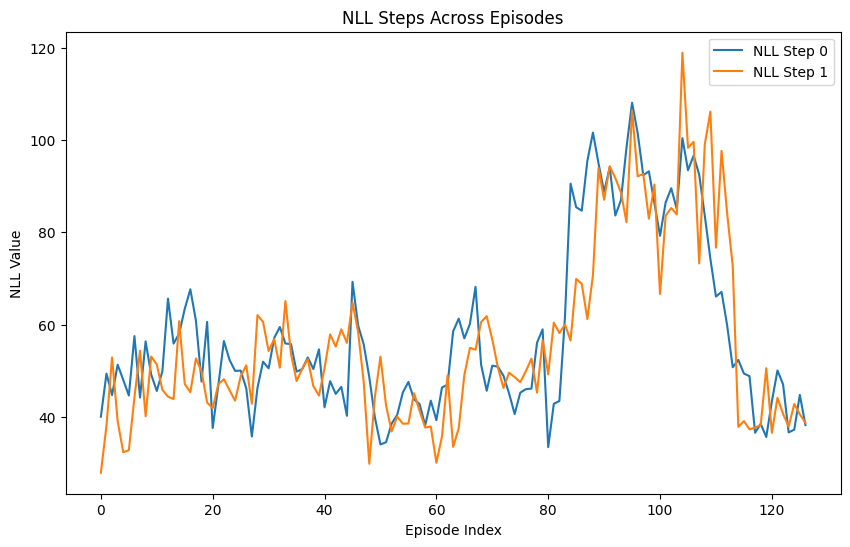

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(nll_steps[:,0], label='NLL Step 0')
plt.plot(nll_steps[:,1], label='NLL Step 1')
plt.xlabel('Episode Index')
plt.ylabel('NLL Value')
plt.title('NLL Steps Across Episodes')
plt.legend()

Original shape: (115, 10, 3, 7)


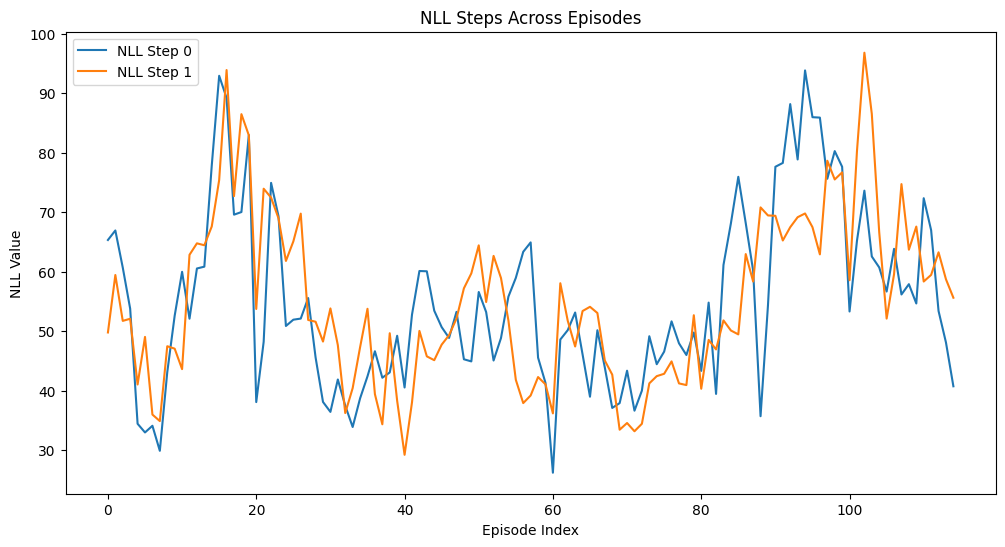

In [4]:
data_5= np.load("../outputs/libero_eval_velocities_2/episodes_npz/task_005_episode_005.npz", allow_pickle=True)
velocities_numpy = data_5["velocitys"][:,:,:,:7]  # [h, N, b, D]
print("Original shape:", velocities_numpy.shape)
nll_steps = data_5["nll_steps"] 
plt.figure(figsize=(12, 6))
plt.plot(nll_steps[:,0], label='NLL Step 0')
plt.plot(nll_steps[:,1], label='NLL Step 1')
plt.xlabel('Episode Index')
plt.ylabel('NLL Value')
plt.title('NLL Steps Across Episodes')
plt.legend()

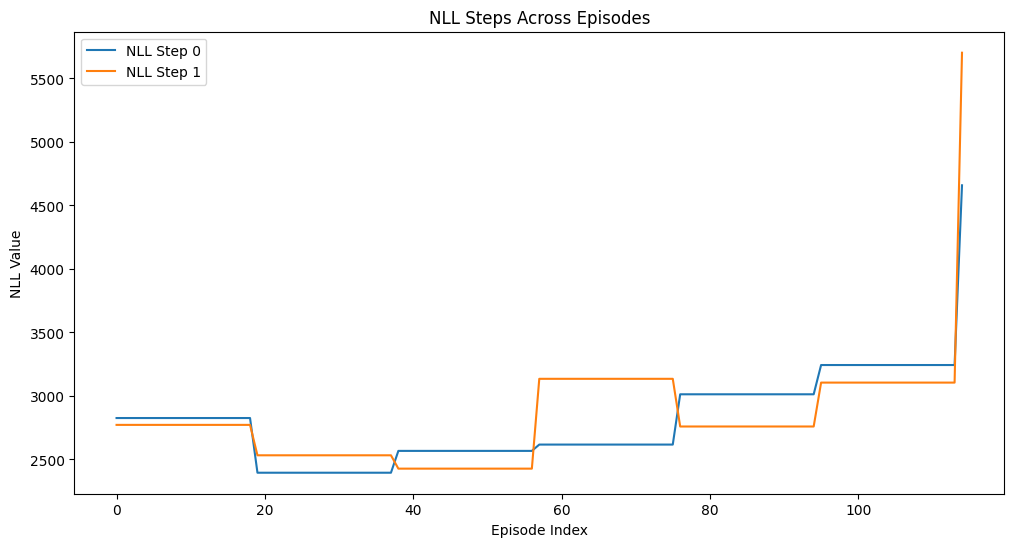

In [5]:
nll_total = data_5["nll_totals"] 
plt.figure(figsize=(12, 6))
plt.plot(nll_total[:,0], label='NLL Step 0')
plt.plot(nll_total[:,1], label='NLL Step 1')
plt.xlabel('Episode Index')
plt.ylabel('NLL Value')
plt.title('NLL Steps Across Episodes')
plt.legend()

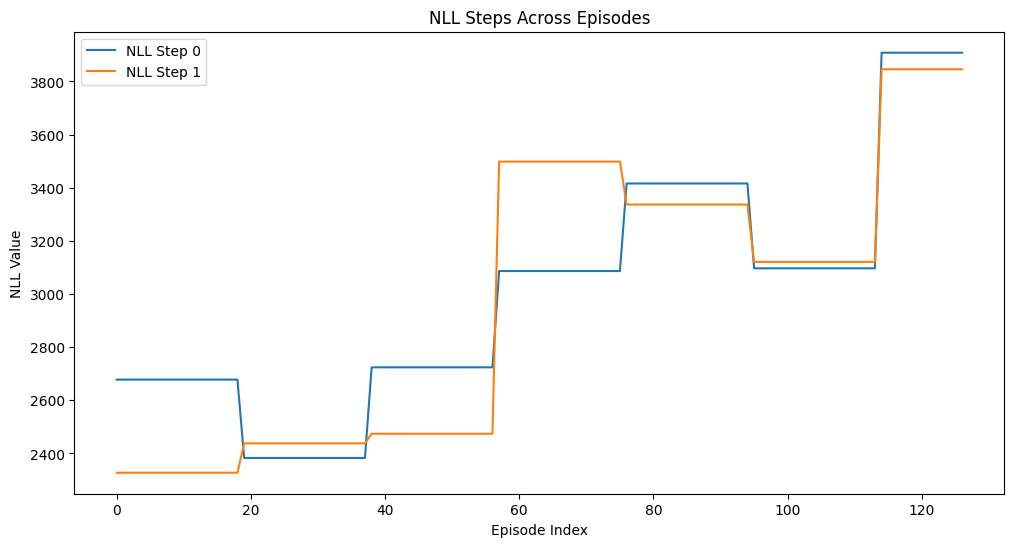

In [6]:
nll_total = data_new["nll_totals"] 
plt.figure(figsize=(12, 6))
plt.plot(nll_total[:,0], label='NLL Step 0')
plt.plot(nll_total[:,1], label='NLL Step 1')
plt.xlabel('Episode Index')
plt.ylabel('NLL Value')
plt.title('NLL Steps Across Episodes')
plt.legend()

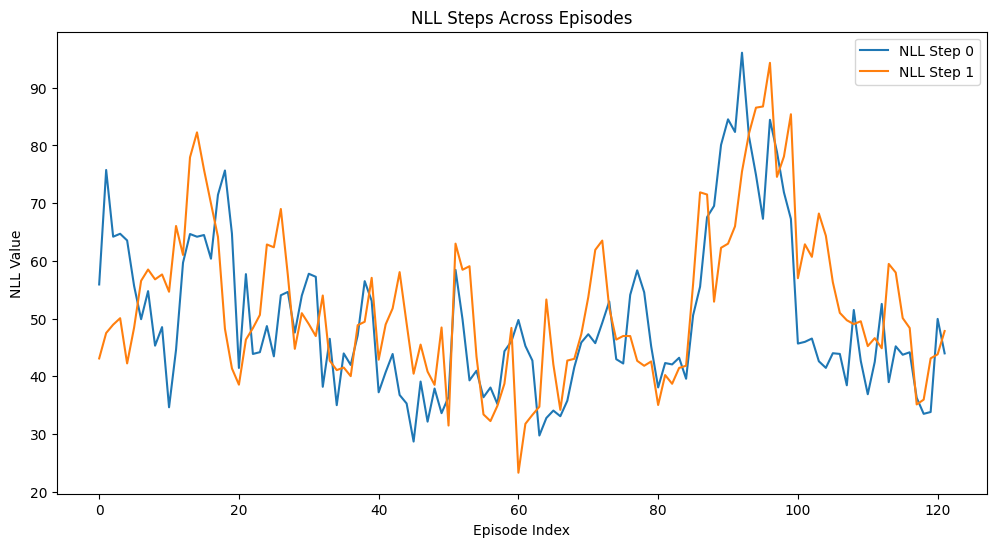

In [7]:
data_1 = np.load("../outputs/libero_eval_velocities_2/episodes_npz/task_001_episode_001.npz", allow_pickle=True)
nll_steps = data_1["nll_steps"] 
plt.figure(figsize=(12, 6))
plt.plot(nll_steps[:,0], label='NLL Step 0')
plt.plot(nll_steps[:,1], label='NLL Step 1')
plt.xlabel('Episode Index')
plt.ylabel('NLL Value')
plt.title('NLL Steps Across Episodes')
plt.legend()

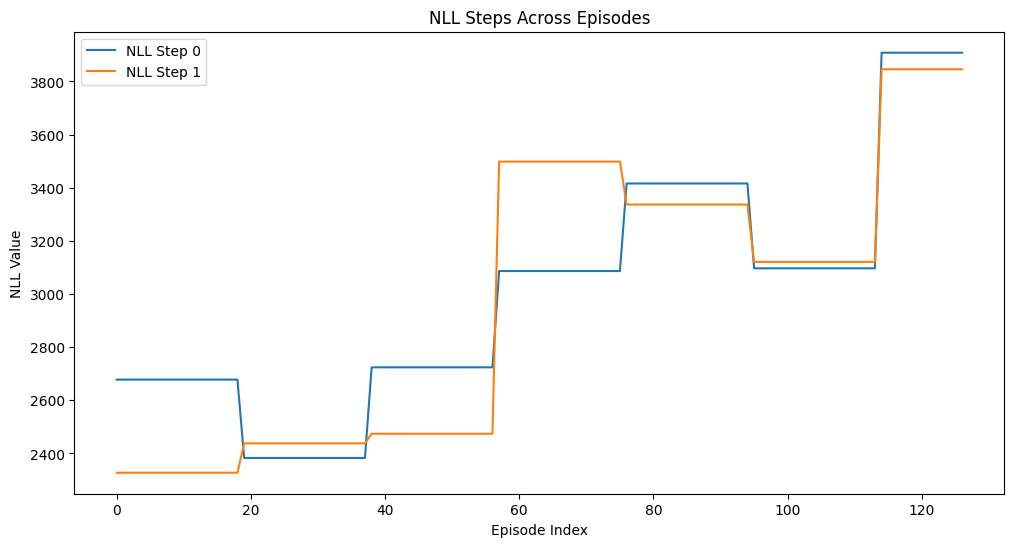

In [8]:
data_0 = np.load("../outputs/libero_eval_velocities_2/episodes_npz/task_000_episode_000.npz", allow_pickle=True)
nll_total = data_0["nll_totals"] 
plt.figure(figsize=(12, 6))
plt.plot(nll_total[:,0], label='NLL Step 0')
plt.plot(nll_total[:,1], label='NLL Step 1')
plt.xlabel('Episode Index')
plt.ylabel('NLL Value')
plt.title('NLL Steps Across Episodes')
plt.legend()

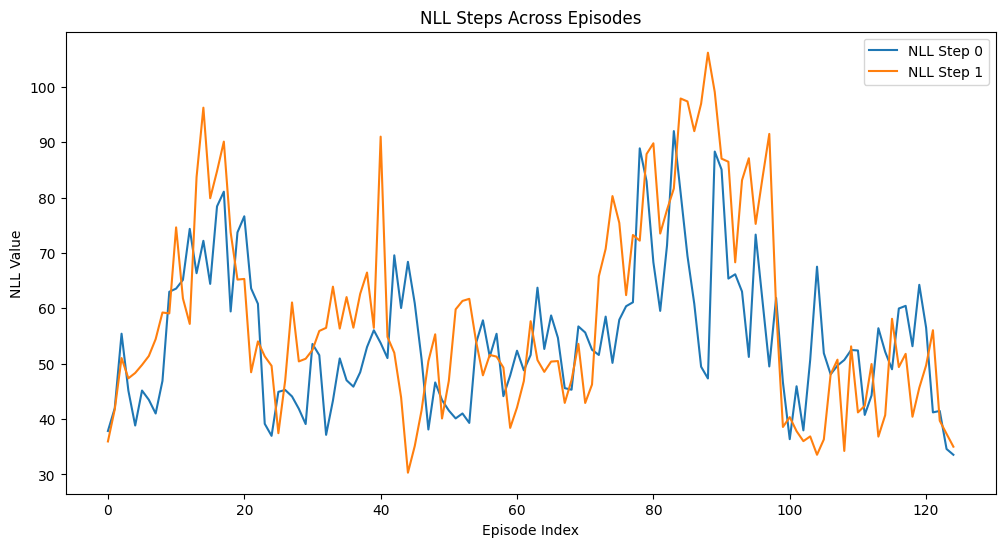

In [9]:
data_2 = np.load("../outputs/libero_eval_velocities_3/episodes_npz/task_002_episode_002.npz", allow_pickle=True)
nll_steps = data_2["nll_steps"] 
plt.figure(figsize=(12, 6))
plt.plot(nll_steps[:,0], label='NLL Step 0')
plt.plot(nll_steps[:,1], label='NLL Step 1')
plt.xlabel('Episode Index')
plt.ylabel('NLL Value')
plt.title('NLL Steps Across Episodes')
plt.legend()

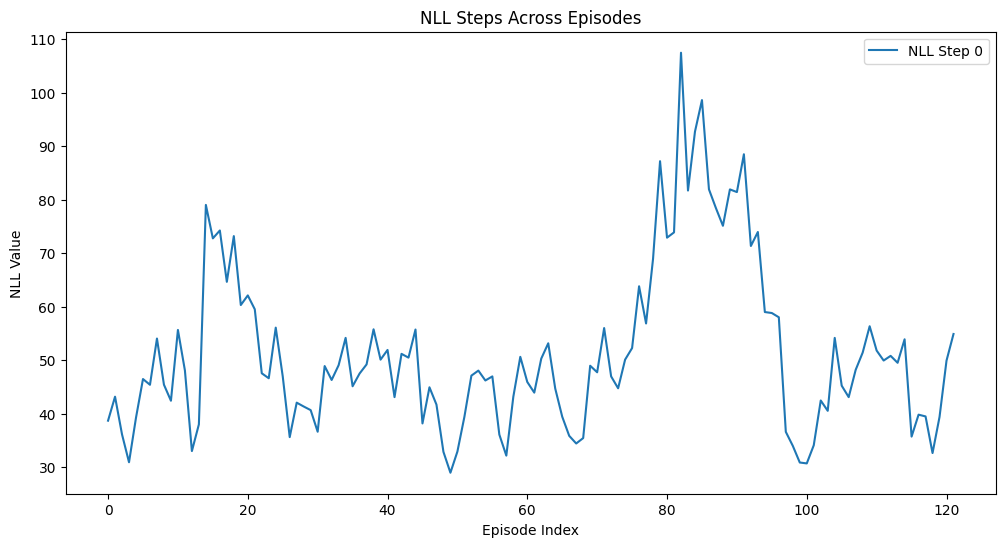

In [10]:
data_3 = np.load("../outputs/libero_eval_velocities_3/episodes_npz/task_003_episode_003.npz", allow_pickle=True)
nll_steps = data_3["nll_steps"]
plt.figure(figsize=(12, 6))
plt.plot(nll_steps[:,0], label='NLL Step 0')
# plt.plot(nll_steps[:,1], label='NLL Step 1')
plt.xlabel('Episode Index')
plt.ylabel('NLL Value')
plt.title('NLL Steps Across Episodes')
plt.legend()


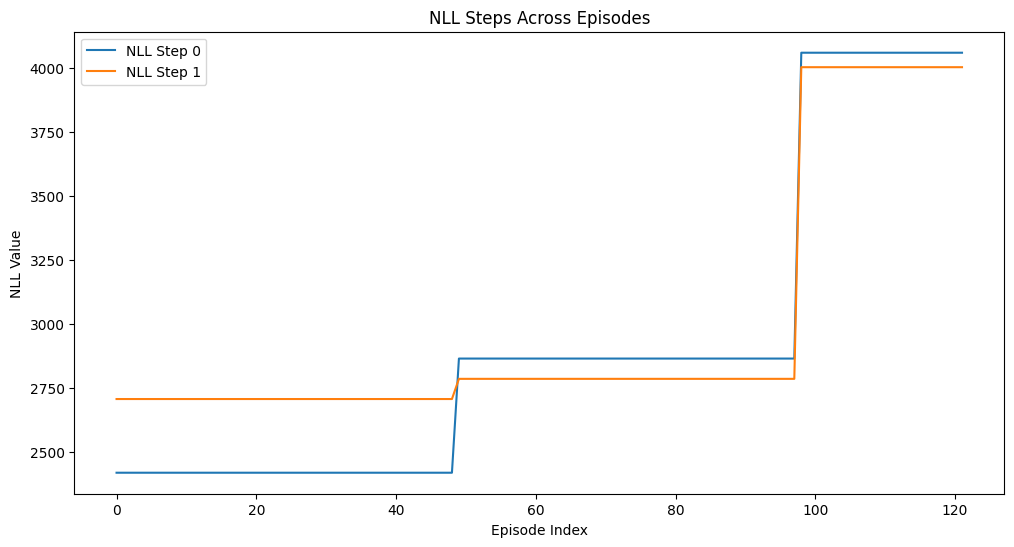

In [11]:
data_3 = np.load("../outputs/libero_eval_velocities_3/episodes_npz/task_003_episode_003.npz", allow_pickle=True)
nll_total = data_3["nll_totals"] 
plt.figure(figsize=(12, 6))
plt.plot(nll_total[:,0], label='NLL Step 0')
plt.plot(nll_total[:,1], label='NLL Step 1')
plt.xlabel('Episode Index')
plt.ylabel('NLL Value')
plt.title('NLL Steps Across Episodes')
plt.legend()


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import math

def plot_all_npz_nll_steps(
    npz_dir="../outputs/libero_eval_velocities_3/episodes_npz",
    step_indices=(0, 1),
    data_indices="nll_steps",
    ncols=2,
    figsize_per_plot=(7, 2.5),
    save_path="nll_steps_summary.png",
    max_files=None,
):
    npz_dir = Path(npz_dir)

    files = sorted(npz_dir.glob("*.npz"))

    if max_files is not None:
        files = files[:max_files]

    if len(files) == 0:
        print(f"No npz files found in: {npz_dir}")
        return

    n_files = len(files)
    nrows = math.ceil(n_files / ncols)

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(figsize_per_plot[0] * ncols, figsize_per_plot[1] * nrows),
        squeeze=False,
    )

    for idx, file_path in enumerate(files):
        row = idx // ncols
        col = idx % ncols
        ax = axes[row][col]

        data = np.load(file_path, allow_pickle=True)
        nll_steps = data[data_indices]

        # nll_steps shape 通常是 [T, chunk_size]
        for s in step_indices:
            if s < nll_steps.shape[1]:
                ax.plot(nll_steps[:, s], label=f"batch {s}")

        ax.set_title(file_path.stem, fontsize=9)
        ax.set_xlabel("Episode Step")
        ax.set_ylabel("NLL")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    # 删除多余的空 subplot
    for idx in range(n_files, nrows * ncols):
        row = idx // ncols
        col = idx % ncols
        fig.delaxes(axes[row][col])

    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

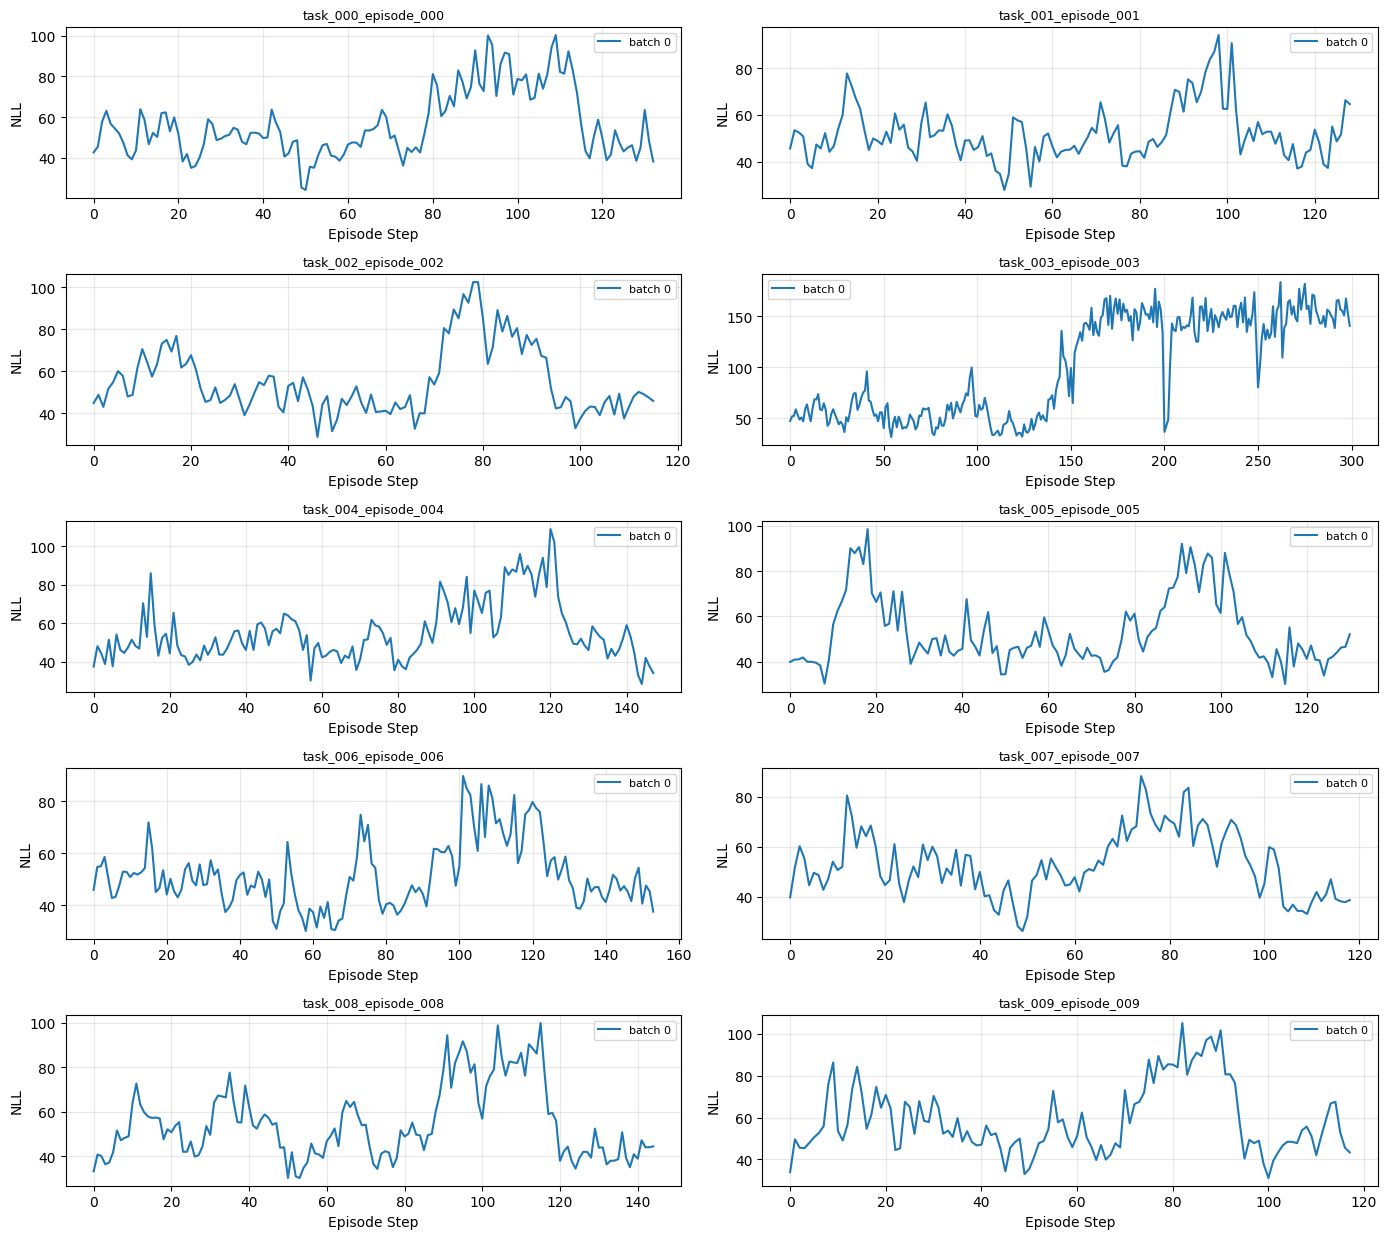

In [ ]:
plot_all_npz_nll_steps(
    npz_dir="../outputs/libero_spatial_eval_2_noise_action_20steps/episodes_npz",
    step_indices=(0,),
    ncols=2,
    figsize_per_plot=(7, 2.5),
    save_path="./out/nll_steps_summary_spatial_eval_2_noise.png",
)

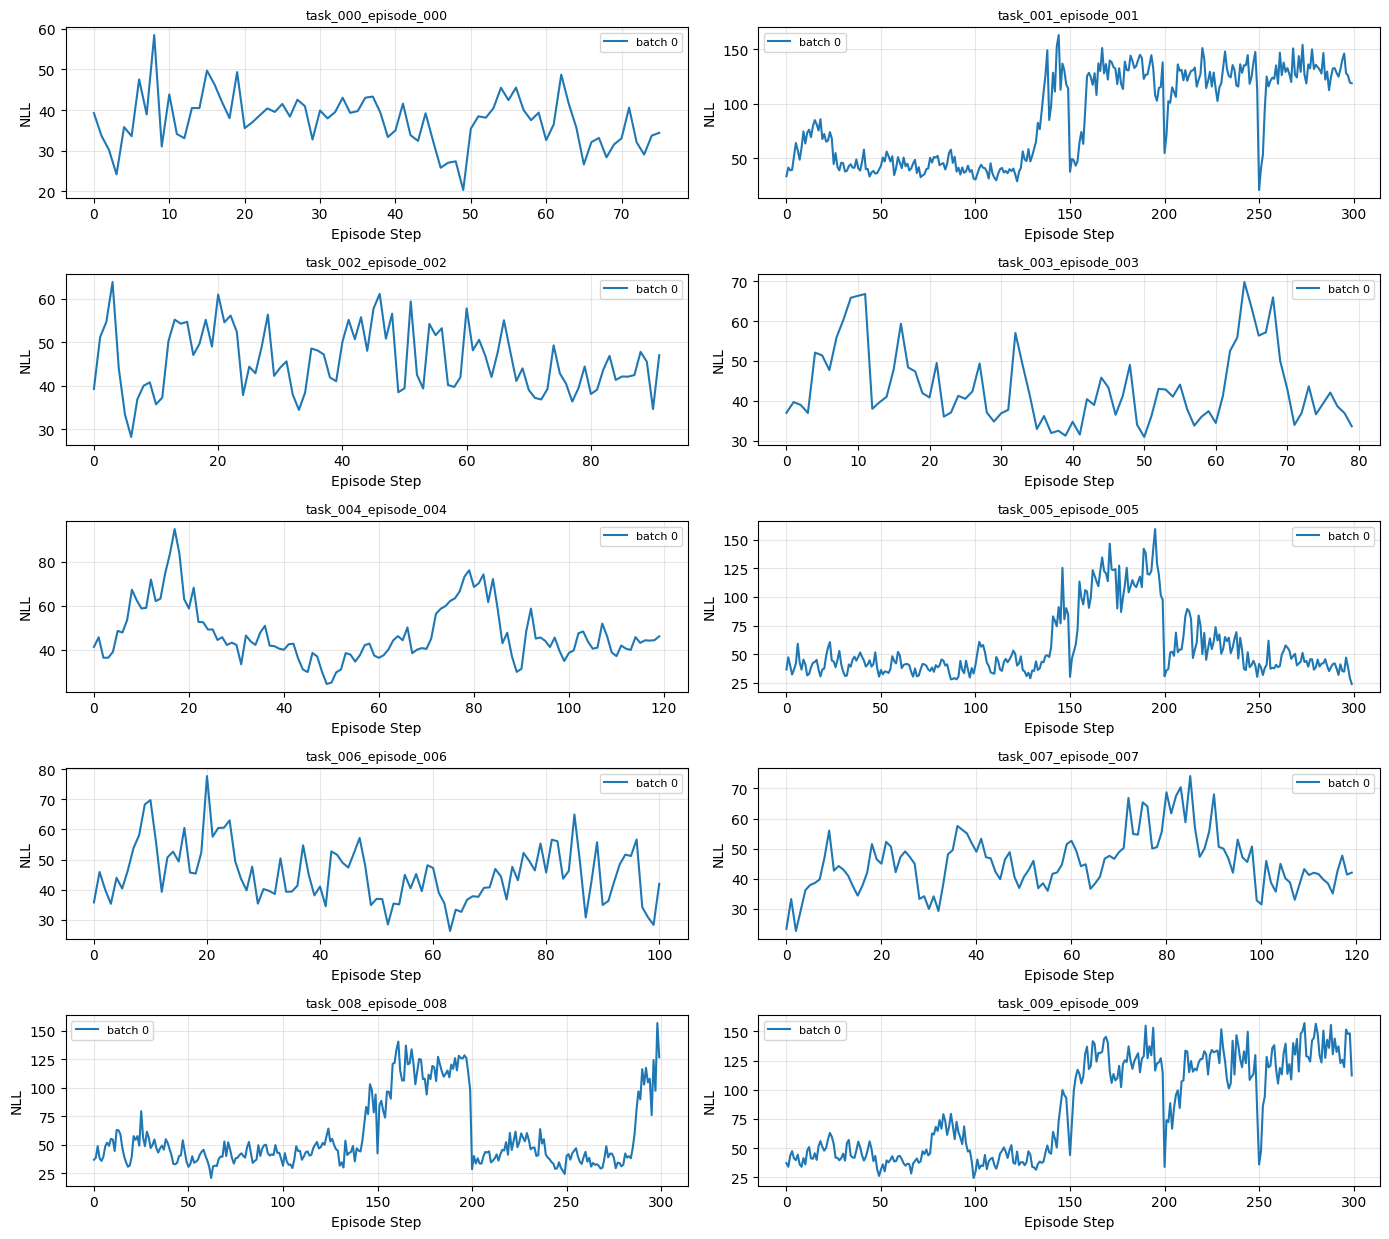

In [ ]:
plot_all_npz_nll_steps(
    npz_dir="../outputs/libero_spatial_eval_2/episodes_npz",
    # data_indices="nll_totals",
    step_indices=(0,),
    ncols=2,
    save_path="out/nll_steps_summary_spatial_eval_2.png",
)

In [27]:
data = np.load("../outputs/libero_spatial_eval_2_noise_action_20steps/episodes_npz/task_003_episode_003.npz", allow_pickle=True)
nll_steps = data["nll_steps"]
nll_totals = data["nll_totals"]
print("nll_steps shape:", nll_steps[:100])
# print("nll_totals shape:", nll_totals.shape)

nll_steps shape: [[23.89486312866211 26.05951690673828 26.215396881103516]
 [23.054157257080078 23.015350341796875 26.064144134521484]
 [21.82840347290039 23.129730224609375 30.822254180908203]
 [22.538040161132812 29.46951675415039 25.631027221679688]
 [24.147315979003906 25.645538330078125 23.943626403808594]
 [26.678375244140625 26.302509307861328 26.640451431274414]
 [27.03835105895996 34.60930633544922 24.07208824157715]
 [28.571006774902344 28.00039291381836 26.920997619628906]
 [26.934965133666992 26.62002944946289 28.999523162841797]
 [25.416973114013672 26.039113998413086 26.176925659179688]
 [26.24843978881836 31.168590545654297 24.014144897460938]
 [28.05431365966797 27.600236892700195 24.673871994018555]
 [25.82867431640625 28.048601150512695 29.12423324584961]
 [28.565500259399414 27.832698822021484 28.75716209411621]
 [28.424081802368164 25.943750381469727 31.65863037109375]
 [27.48432731628418 31.234888076782227 25.800119400024414]
 [26.85077476501465 28.243915557861328 

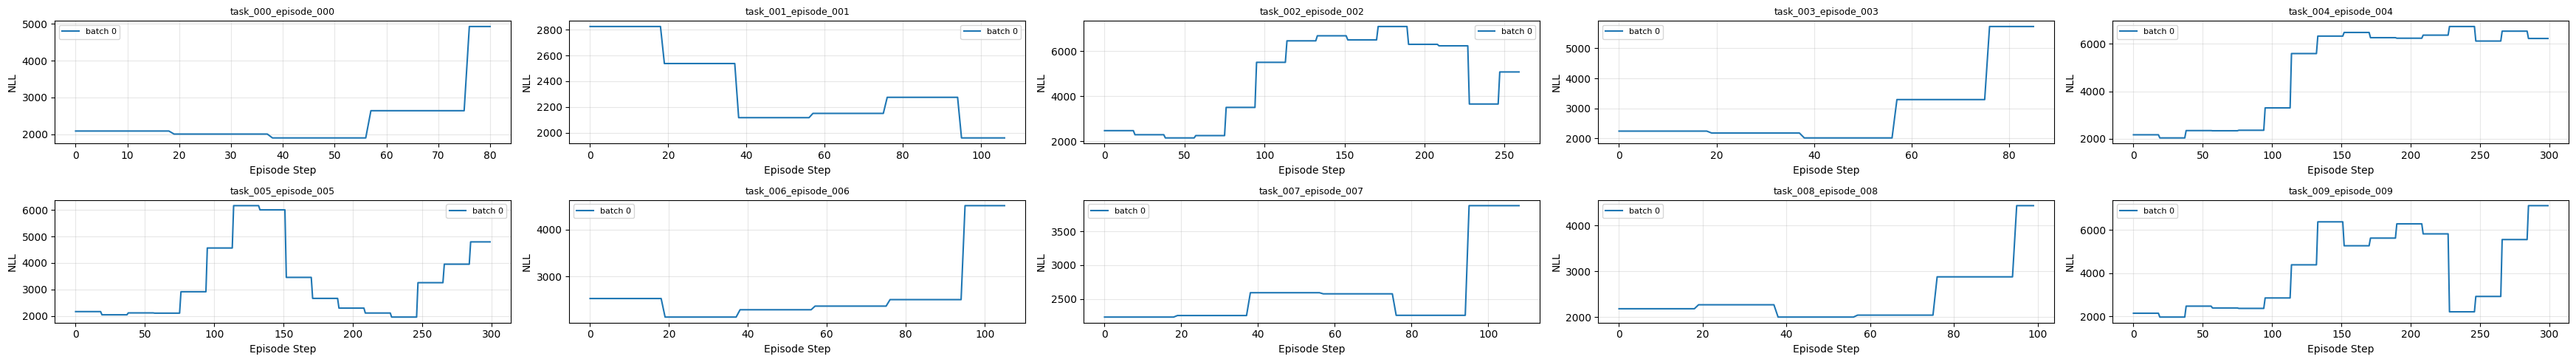

In [15]:
plot_all_npz_nll_steps(
    npz_dir="../outputs/libero_spatial_eval_1/episodes_npz",
    data_indices="nll_totals",
    step_indices=(0,),
    ncols=5,
    save_path="./nll_totals_summary_spatial_1.png",
)

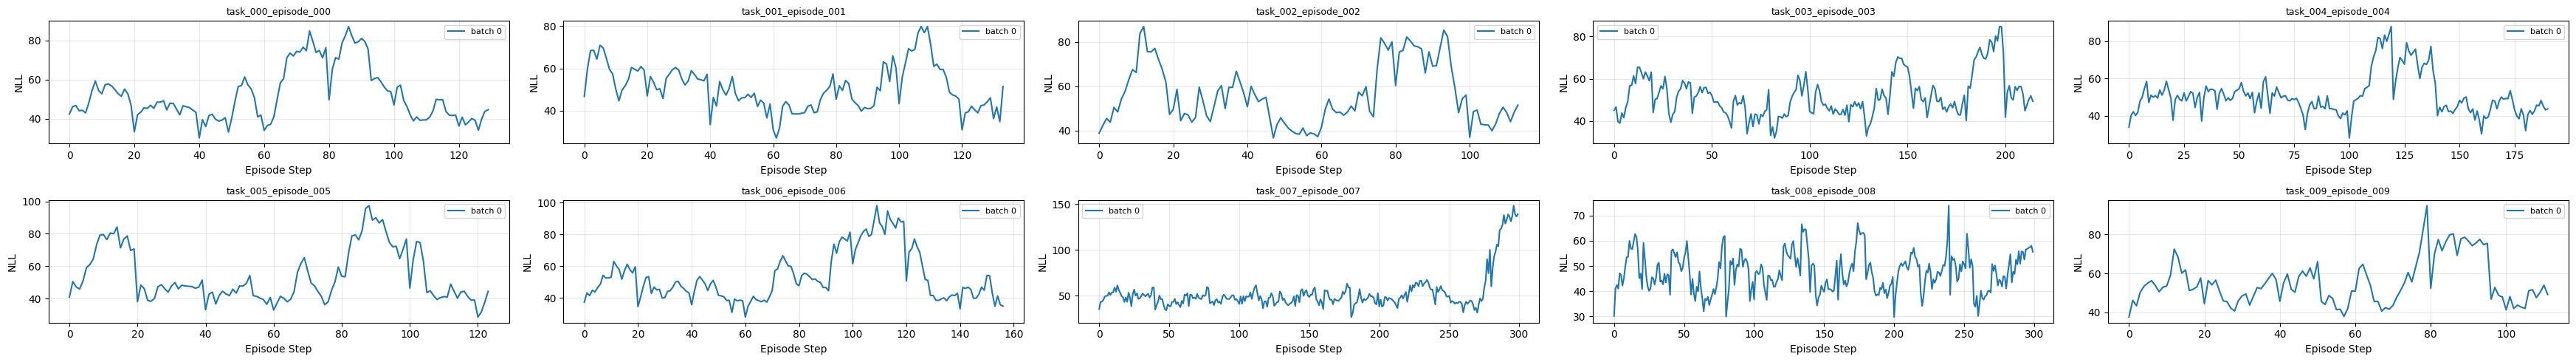

In [16]:
plot_all_npz_nll_steps(
    npz_dir="../outputs/libero_eval_velocities_4/episodes_npz",
    # data_indices="nll_totals",
    step_indices=(0,),
    ncols=5,
)

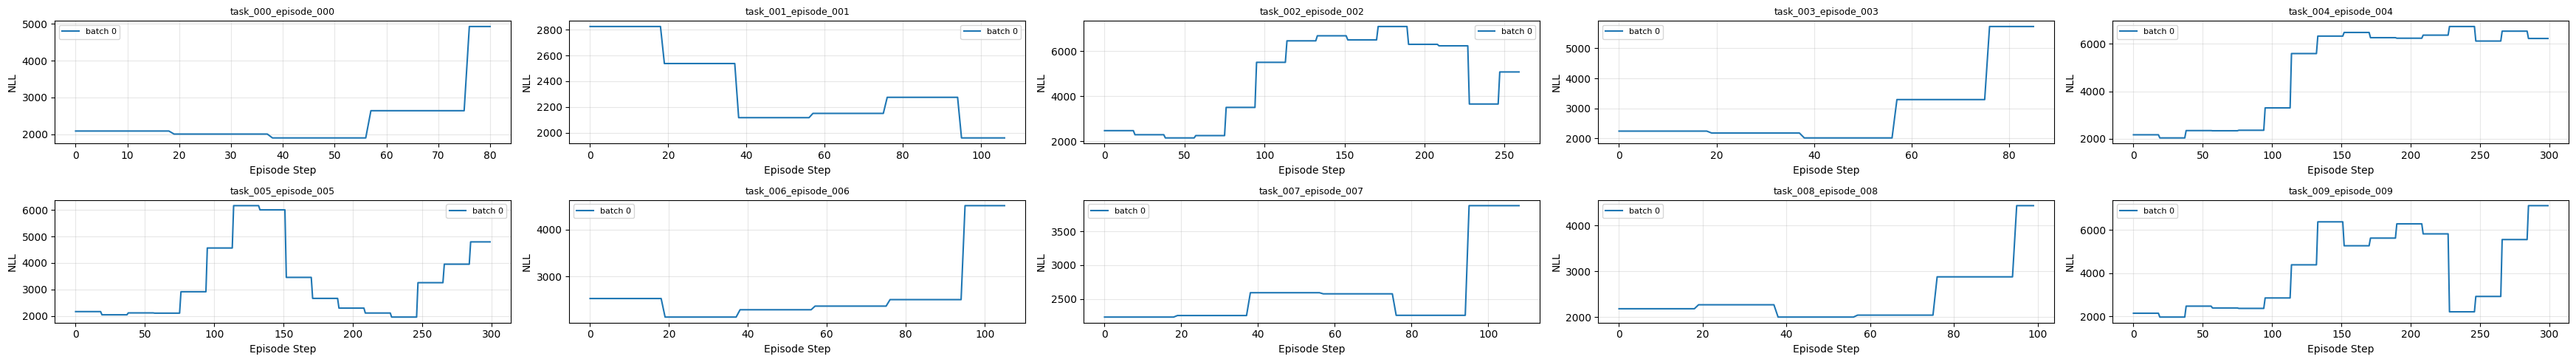

In [17]:
plot_all_npz_nll_steps(
    npz_dir="../outputs/libero_spatial_eval_1/episodes_npz",
    data_indices="nll_totals",
    step_indices=(0,),
    ncols=5,
)